# Imports and Definitions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal as mvn
from scipy.stats import binned_statistic_2d
from scipy.ndimage import zoom, gaussian_filter
from tqdm import tqdm
from random import choice
from inference_tools import ParticleFilter, crng, HilbertSorter, ConditionedBridge
from matplotlib import patches as mpatches
import matplotlib as mpl
from matplotlib import cm as cm

In [2]:
mpl.rcParams['figure.dpi'] = 90

In [3]:
sorter = HilbertSorter(depth=9, dims=2)
bridge_gen = ConditionedBridge()

# Equation of Motion

The Equation of Motion for a simple ballistic brownian swimmer. It has rotational diffusion and active propulsion, but no translational diffusion.

## Definition

In [4]:
def abp_sde(T0, T1, X0, params):
    
    output_hires = params.get('output_hires', False)
    omit_bridges = params.get('omit_bridges', False)
    use_tqdm = params.get('use_tqdm', False)
    target_shift_P = params.get('target_shift_PHI', 0)
    target_slope_P = params.get('target_slope_PHI', 0)
    spread = params.get('bridge_spread_rate', 0)
    BridgeGen = params['BridgeGen']
    RNG = params['RNG']
    logDr = params['logDr']
    logv  = params['logv']
    Dr    = np.exp(logDr)
    v     = np.exp(logv)
    _id = params.get('id', -1)
    dt  = params['dt']
    
    X = X0.copy()
    T = T0
    step = 0
    
    if output_hires:
        hires  = [X.copy()]
        hiresT = [T]
        
    n_steps = int((T1 - T0) / dt + 1)
    n_parts = X.shape[0]
    dt_ = (T1 - T0) / n_steps
    
    if not omit_bridges:
        
        slope_factor = 1 / (np.sqrt(2 * Dr * dt_))
        shift_factor = 1 / (np.sqrt(2 * Dr * dt_) * v * dt_)
        
        slopeP = target_slope_P * np.ones((n_parts,)) * slope_factor
        shiftP = target_shift_P * (np.ones((n_parts,)) + spread * np.random.randn(n_parts)) * shift_factor
        
        bridge_res_P = BridgeGen.get(n_steps + 1, shiftP, slopeP, ('abpsdePbridgegen', _id, T0, T1), 0.0, RNG)
        
        logl = np.mean(-(slopeP/bridge_res_P['std1'])**2 - (shiftP/bridge_res_P['std2'])**2) / 2 + np.log(slope_factor) + np.log(shift_factor)
        
        wP  = bridge_res_P['w']
        dwP = np.diff(wP, axis=0)
        dwP = np.concatenate([wP[[0],:], dwP])
        ddP = np.diff(dwP, axis=0).T

        w = ddP
        
    else:
        w = RNG.get(('abpsde_full', _id, T0, T1), (n_parts, n_steps), corr=0)
        logl = 0

    if use_tqdm:  
        R_ = tqdm(range(n_steps))
    else:
        R_ = range(n_steps)
        
    for k in R_:

        ''' Integrate the EOM '''

        dx = np.cos(X[:, 2])
        dy = np.sin(X[:, 2])
        drift = np.stack([dx*v, dy*v, np.zeros_like(dx)], axis=1)

        X[..., -1] += np.sqrt(dt_) * w[..., k] * np.sqrt(2 * Dr)
        X += dt_ * drift
        
        if output_hires:
            hires.append(X.copy())
            hiresT.append(T)
    
    res_dict = dict(X1=X, logl=logl)
    
    if output_hires:
        res_dict['per_particle_streams'] = dict(hires=np.stack(hires, -1))

    return res_dict

In [5]:
def abp_run_simple(X0=np.zeros((1, 3)),
                   dt=1e-1, Tout=np.linspace(0, 1, 11),
                   params=None
                  ):   
    
    if params is None:
        params = dict(RNG=crng(),
                      Dr = 1e-2,
                      v = 1,
                      dt = dt,
                      output_hires=True,
                      BridgeGen=bridge_gen,
                      omit_bridges=True,
                      use_tqdm = False,
                     )

    x = [X0[:, 0]]
    y = [X0[:, 1]]
    phi = [X0[:, 2]]
    Told = 0
    for Tmax in Tout:
        params['RNG'].reroll(0)
        sim_res = abp_sde(Told, Tmax, np.stack([x[-1], y[-1], phi[-1]]).T, params)
        Told = Tmax
        x.append(sim_res['X1'][:, 0])
        y.append(sim_res['X1'][:, 1])
        phi.append(sim_res['X1'][:, 2])

    x = np.stack(x[1:])
    y = np.stack(y[1:])
    
    return dict(x=x, y=y)

## Test

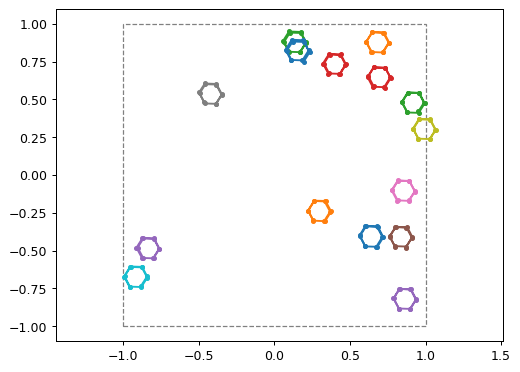

In [6]:
N = 15
dt = 1e-3
v = 1
Tmax = 1

z = v * np.sqrt(Tmax)
X0 = np.random.uniform(size=(N,3)) * [2*z, 2*z, 0*2*np.pi] - [z, z, 0]
Tout=np.linspace(1e-1, Tmax, 12)

params = dict(RNG=crng(),
              logDr = 1,
              logv = np.log(v),
              dt = dt,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
              use_tqdm = False,
              target_slope_PHI =  2 * np.pi/6,
              target_shift_PHI = -0.00123,
             )

res = abp_run_simple(X0, dt, Tout, params)
x = res['x']
y = res['y']

rect = mpatches.Rectangle((-z, -z), 2*z, 2*z, linewidth=1, edgecolor='gray', linestyle='--', facecolor='none')
plt.gca().add_patch(rect)

plt.plot(x,y,'.-')
plt.gca().axis('equal')
plt.show()

# Inference

## Data Generation

In [7]:
_GT_DR_  = 2
_GT_V_   = 3.
_DT_OBS_ = 0.1
_N_OBS_  = 30
_SIG_OBS_ = 1e-3

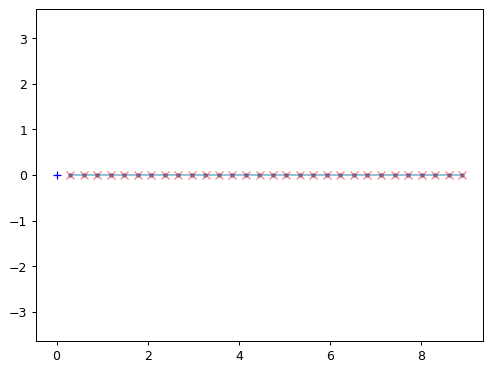

In [24]:
N = 1
dt = 1e-3
v = _GT_V_
Tmax = _DT_OBS_ * _N_OBS_

X0 = np.random.uniform(size=(N,3)) * [0, 0, 0]
Tout=np.linspace(_DT_OBS_, Tmax, _N_OBS_)

params = dict(RNG=crng(),
              logDr = np.log(_GT_DR_),
              logv = np.log(_GT_V_),
              dt = dt,
              output_hires=True,
              BridgeGen=bridge_gen,
              omit_bridges=False,
              use_tqdm = False,
              target_slope_PHI=0.,
              target_shift_PHI=0,
             )

res = abp_run_simple(X0, dt, Tout, params)
GT_X = res['x']
GT_Y = res['y']
OBS_X = GT_X + np.random.normal(scale = _SIG_OBS_, size=GT_X.shape)
OBS_Y = GT_Y + np.random.normal(scale = _SIG_OBS_, size=GT_Y.shape)

plt.plot(GT_X, GT_Y, '.-', alpha=0.5)
plt.plot(OBS_X, OBS_Y, 'xr', alpha=0.5)
plt.plot([0], [0], '+b')
plt.gca().axis('equal')
plt.show()

In [25]:
def abp_logl(X, Y, params):
    sigma = params['sigma_observation']
    return np.nansum( -((X - Y) / sigma) ** 2, axis=1)


def update_bridge_parameters(Y0):
    
    sw_x  = 0   # Swarm location
    sw_y  = 0
    sw_dx = 1  # Swarm direction
    sw_dy = 0
    
    for y0_ in Y0:                
        targ_x = y0_['targ_x']
        targ_y = y0_['targ_y']
        
        x_obs = y0_['Y'][0]
        y_obs = y0_['Y'][1]
        
        targ_dx = y0_['targ_dx']
        targ_dy = y0_['targ_dy']
        
        norm_ = np.sqrt(targ_dx**2 + targ_dy**2)
        targ_dx /= norm_
        targ_dy /= norm_
        
        y0_['targ_dx'] = targ_dx
        y0_['targ_dy'] = targ_dy
        
        dx = targ_x - sw_x
        dy = targ_y - sw_y
        
        # Projection of the shift
        p = dx * sw_dx + dy * sw_dy
        dx_orth = p * sw_dx - dx
        dy_orth = p * sw_dy - dy
        shift = sw_dy * dx_orth - sw_dx * dy_orth
        y0_['target_shift_PHI'] = 1 * shift
        angle = np.arccos(sw_dx * targ_dx + sw_dy * targ_dy) * np.sign(-sw_dy * targ_dx + sw_dx * targ_dy)
        y0_['target_slope_PHI'] = angle
        
        dx_obs = x_obs - sw_x
        dy_obs = y_obs - sw_y
        
        p_obs = dx_obs * sw_dx + dy_obs * sw_dy
        
        y0_['targ_x'] = sw_x + p_obs * sw_dx - shift * sw_dy
        y0_['targ_y'] = sw_y + p_obs * sw_dy + shift * sw_dx
        
        sw_x = y0_['targ_x']
        sw_y = y0_['targ_y']
        sw_dx = targ_dx
        sw_dy = targ_dy

## Inference

In [26]:
N_parts = 100

In [27]:
params = dict(RNG=crng(),
              logDr = np.log(_GT_DR_*1.),
              logv = np.log(_GT_V_*1.),
              dt = 1e-2,
              HilbertSort_dims = (0,1),
              HilbertSorter = sorter,
              sigma_observation = _SIG_OBS_,
              output_hires=True,
              output_trajectory=True,
              BridgeGen=bridge_gen,
              omit_bridges=True,
              HilbertSort_useObservationCenter = False,
              observation_parameters = ['target_shift_PHI', 'target_slope_PHI'],

              sample_parameters = ['targ_x', 'targ_y', 'targ_dx', 'targ_dy'],
             )


In [46]:
Y0 = [dict(T=T,
           Y=np.array([float(X), float(Y), np.nan]),
           targ_x = float(X),
           targ_y = float(Y),
           targ_dx = 1,
           targ_dy = 0,
          )
      for T, X, Y in zip(Tout, OBS_X, OBS_Y)
     ]

for y1, y2 in zip(Y0, Y0[1:]):
    dx = y2['targ_x'] - y1['targ_x']
    dy = y2['targ_y'] - y1['targ_y']
    y1['targ_dx'] = dx
    y1['targ_dy'] = dy

#Y0 = Y0[:1]
cutoff = 2
update_bridge_parameters(Y0)
#Y0

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_71173/3117842660.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Y=np.array([float(X), float(Y), np.nan]),
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_71173/3117842660.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  targ_x = float(X),
/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_71173/3117842660.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  targ_y = float(Y),


In [47]:
#cutoff += 1

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_71173/708285790.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('winter', count)
100%|██████████████████████████████████████| 3000/3000 [00:04<00:00, 726.81it/s]


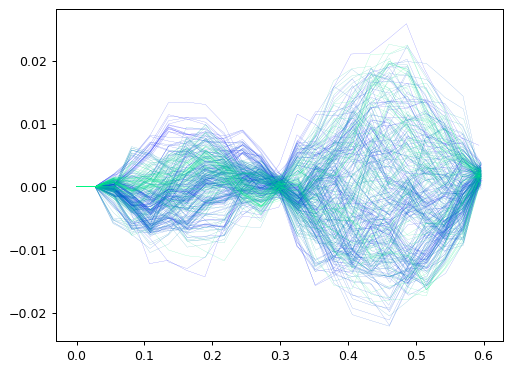

In [48]:
#cutoff += 1
accept = 0

Drpost = []
vpost = []

count = 3000
cmap = cm.get_cmap('winter', count)

#cutoff = 15
Y0_ = Y0[:cutoff]

logl = -np.inf
#params['observation_parameter_adapt_rate'] = dict(target_shift_PHI=0.01, target_slope_PHI=0.01)

adapt_rate = 0.00005
angle_adapt_rate = 0.00025
params['sample_parameter_adapt_rate'] = dict(targ_x = adapt_rate,
                                             targ_y = adapt_rate,
                                             targ_dx = angle_adapt_rate,
                                             targ_dy = angle_adapt_rate,
                                            )

params['sigma_observation'] = 1e-3
params['bridge_spread_rate'] = 0.0
for _ in tqdm(range(count)):
    
    X0 = (np.zeros((N_parts, 3))
      #+ np.random.randn(N_parts, 3) * [_SIG_OBS_, _SIG_OBS_, 0]
      #+ (0.5*np.random.uniform(size=(N_parts, 3))-1) * [0, 0, 0.1*np.pi] 
     )

    params['RNG'].reroll(0.999)
    old_logv = params['logv']
    old_logDr = params['logDr']
    
    #params['logv'] += 0.05*(np.random.rand() - 0.5)
    #params['logDr'] += 0.02*(np.random.rand() - 0.5)
    
    yt_ = choice(Y0_)
    #yt_ = Y0_[-1]
    for yt_ in Y0_:
        for param_name in params['sample_parameters']:
            yt_[param_name + '_old'] = yt_[param_name]
            yt_[param_name] += np.random.randn() * params["sample_parameter_adapt_rate"][param_name]

    
    update_bridge_parameters(Y0)
    filt_res = ParticleFilter(abp_logl, abp_sde, X0, Y0_, params)
    logl_propose = filt_res['logl']
    
    a = np.random.rand()
    thresh = 1 if logl_propose > logl else np.exp(logl_propose - logl)
    if a > thresh:
        for yt_ in Y0_:
            for param_name in params['sample_parameters']:
                yt_[param_name] = yt_[param_name + '_old']
        
        #params['logv'] = old_logv
        #params['logDr'] = old_logDr
        params['RNG'].revert()
        #plt.plot(filt_res['trajectory'][0,:], filt_res['trajectory'][1,:], '--', linewidth=0.5, c='k', markersize=0.9, alpha=0.01)
        
    else:
        accept += 1
        logl = logl_propose
        #r = filt_res['streams']['hires']
        x_ = filt_res['trajectory'][0,:]
        y_ = filt_res['trajectory'][1,:]
        x_ = filt_res['streams']['hires'][0,:]
        y_ = filt_res['streams']['hires'][1,:]
        #x_ = np.pad(x_, ((1,0),))
        #y_ = np.pad(y_, ((1,0),))
        plt.plot(x_, y_, '-', linewidth=0.1, c=cmap(_), markersize=0.9)
    
    vpost.append(np.exp(params['logv']))
    Drpost.append(np.exp(params['logDr']))

plt.savefig("sticky_chain.png", dpi=600)

In [49]:
filt_res['streams']['hires'].shape

(3, 24)

accept = 24.7%


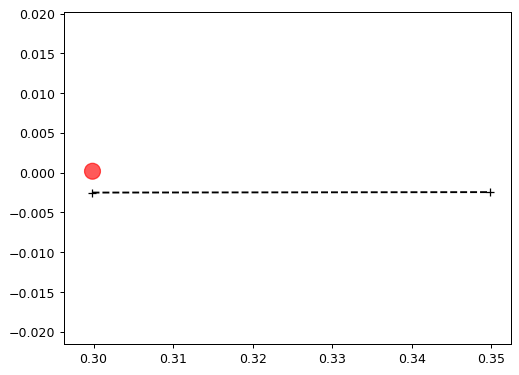

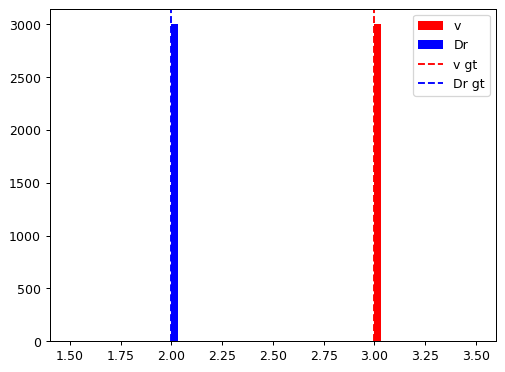

Text(0, 0.5, 'Dr')

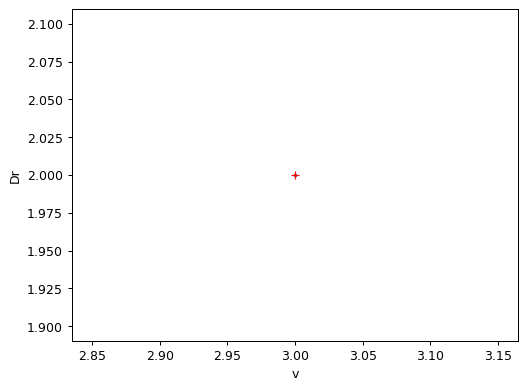

In [32]:
 print(f"accept = {100 * accept / count:.1f}%")
#plt.gca().axis('equal')
vec_len_ = 0.05
for yt_ in Y0_:
    y = yt_['Y']
    circ = mpatches.Circle(y[:2], radius=params['sigma_observation']*1, color='r', zorder=10000, alpha=0.65)
    plt.gca().add_patch(circ)
    plt.plot([yt_['targ_x'], yt_['targ_x'] + vec_len_ * yt_['targ_dx']],
             [yt_['targ_y'], yt_['targ_y'] + vec_len_ * yt_['targ_dy']],
             '--+k'
            )

#plt.xlim([-0.1, 4.2])
#print("v=", params['v'])
plt.gca().axis('equal')
#plt.gca().axis('equal')

#plt.plot(GT_X[:cutoff], GT_Y[:cutoff], '--k')

plt.show()
plt.hist(vpost, label='v', color='r', bins=30)
plt.hist(Drpost, label='Dr', color='b', bins=30)
plt.axvline(_GT_V_, linestyle='--', c='r', label='v gt')
plt.axvline(_GT_DR_, linestyle='--', c='b', label='Dr gt')
plt.legend()

plt.show()

plt.plot(vpost, Drpost, '.', markersize=2, alpha=0.1)
plt.plot([_GT_V_], [_GT_DR_], '+r')
plt.xlabel("v")
plt.ylabel("Dr")

In [33]:
cutoff

1

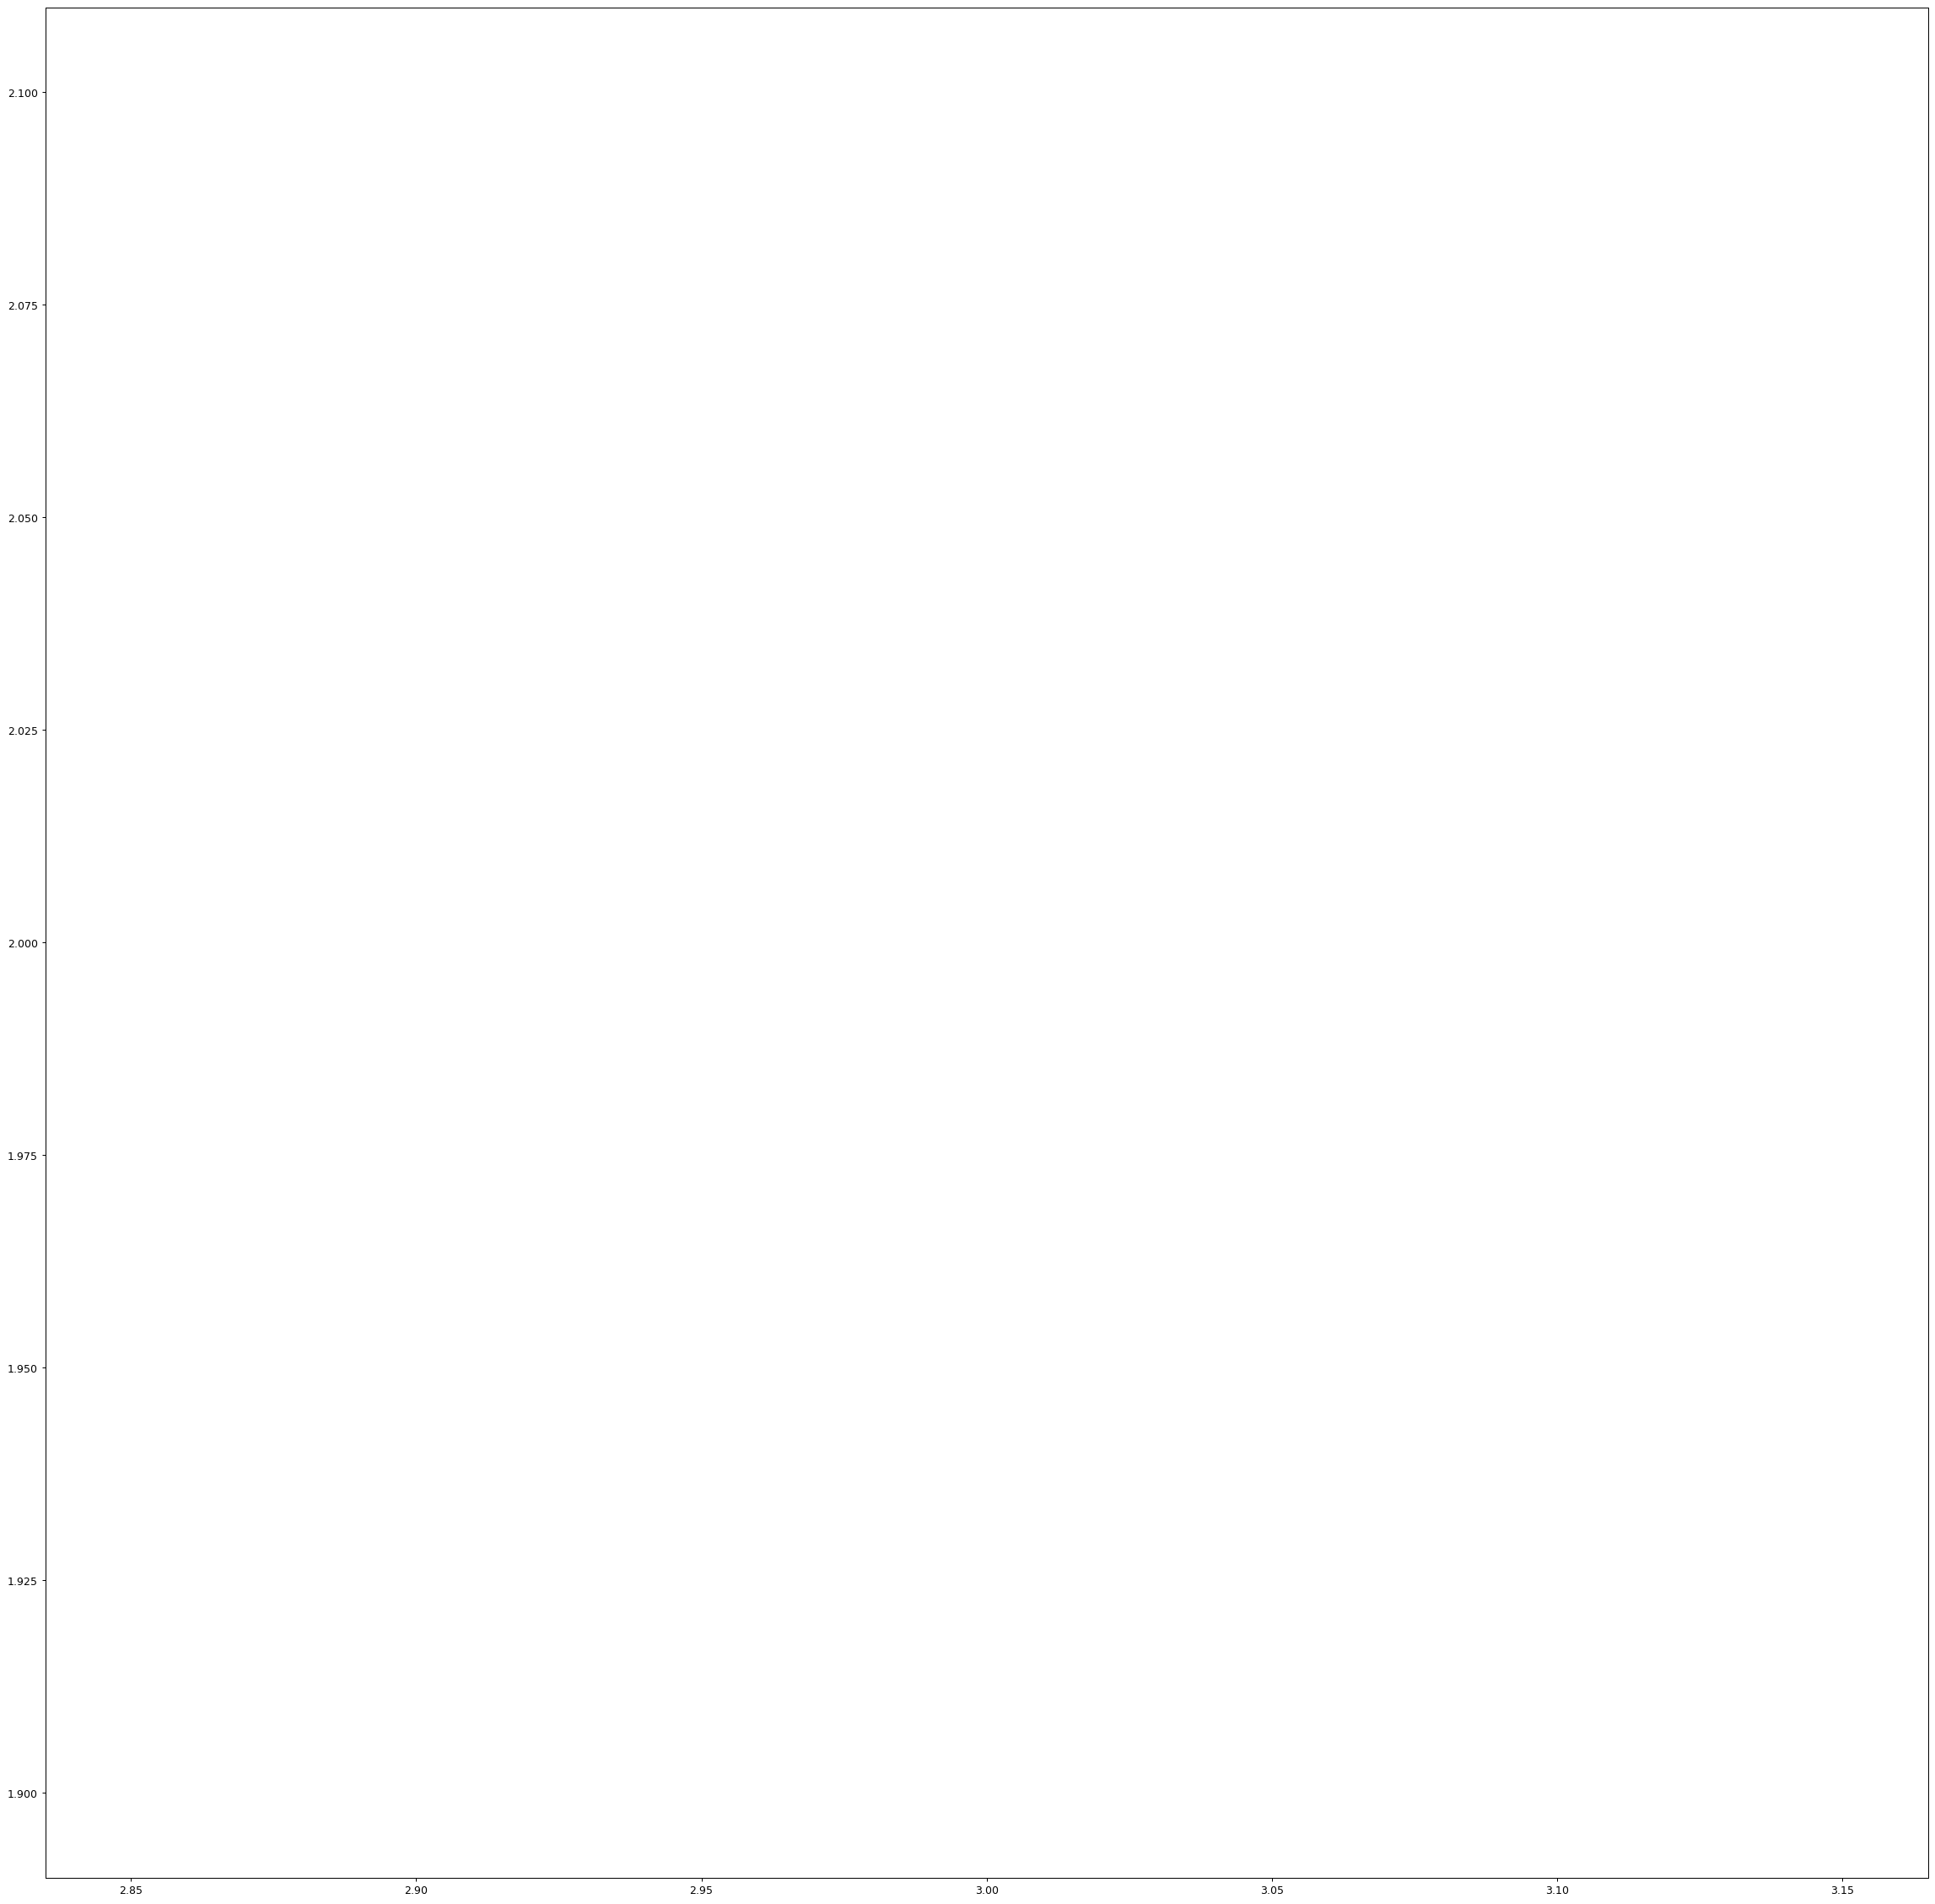

In [45]:
plt.figure(figsize=(32,32))
plt.plot(vpost, Drpost, '-', linewidth=0.1, alpha=1)
#plt.gca().axis('equal')